### Visualização de dados para identificação e comparação de eventos

Este notebook tem como objetivo apresentar pequenas partes dos dados com diferentes classes de eventos para comparar e perceber visualmente a diferença entre elas.

In [2]:
# realizando o carregamento dos dados MNE

import mne

# Carregando os dados do arquivo .fif de epochs
epochs = mne.read_epochs('s08-epo.fif')

Reading /home/rhubner/sandbox/tutoriais/SomeFeatures/s08-epo.fif ...
Isotrak not found
    Found the data of interest:
        t =       0.00 ...     124.00 ms
        0 CTF compensation matrices available
Not setting metadata
3764 matching events found
No baseline correction applied
0 projection items activated


In [6]:
import matplotlib.pyplot as plt

def plots_evoked(evoked_data):
    # grade de 4 linhas e 2 colunas para os 8 canais
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(evoked_data.ch_names):
        ax = axes[i]
        evoked_chan = evoked_data.copy().pick(picks=[channel_name])
        times = evoked_chan.times
        data = evoked_chan.get_data()[0]

        ax.plot(times, data, label=channel_name, color="darkblue")
        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        # rótulo do eixo Y apenas na primeira coluna
        if i % 2 == 0:
            ax.set_ylabel("Amplitude")
        # rótulo do eixo X apenas na última linha
        if i >= 6:
            ax.set_xlabel("Tempo (s)")

    plt.tight_layout()
    plt.show()

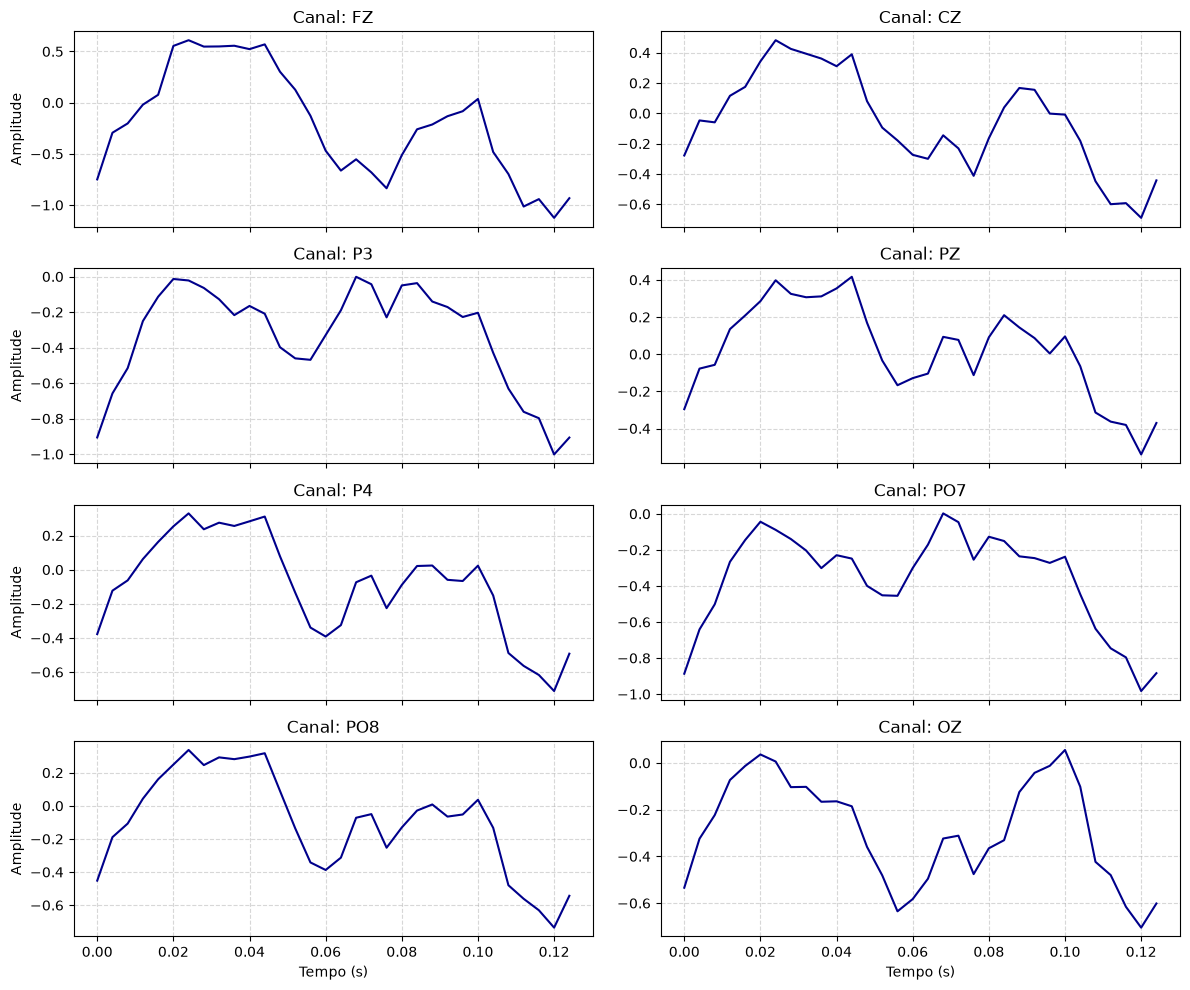

In [ ]:
# plot filtrando pela média dos "hits"
plots_evoked(epochs["hit"].average())

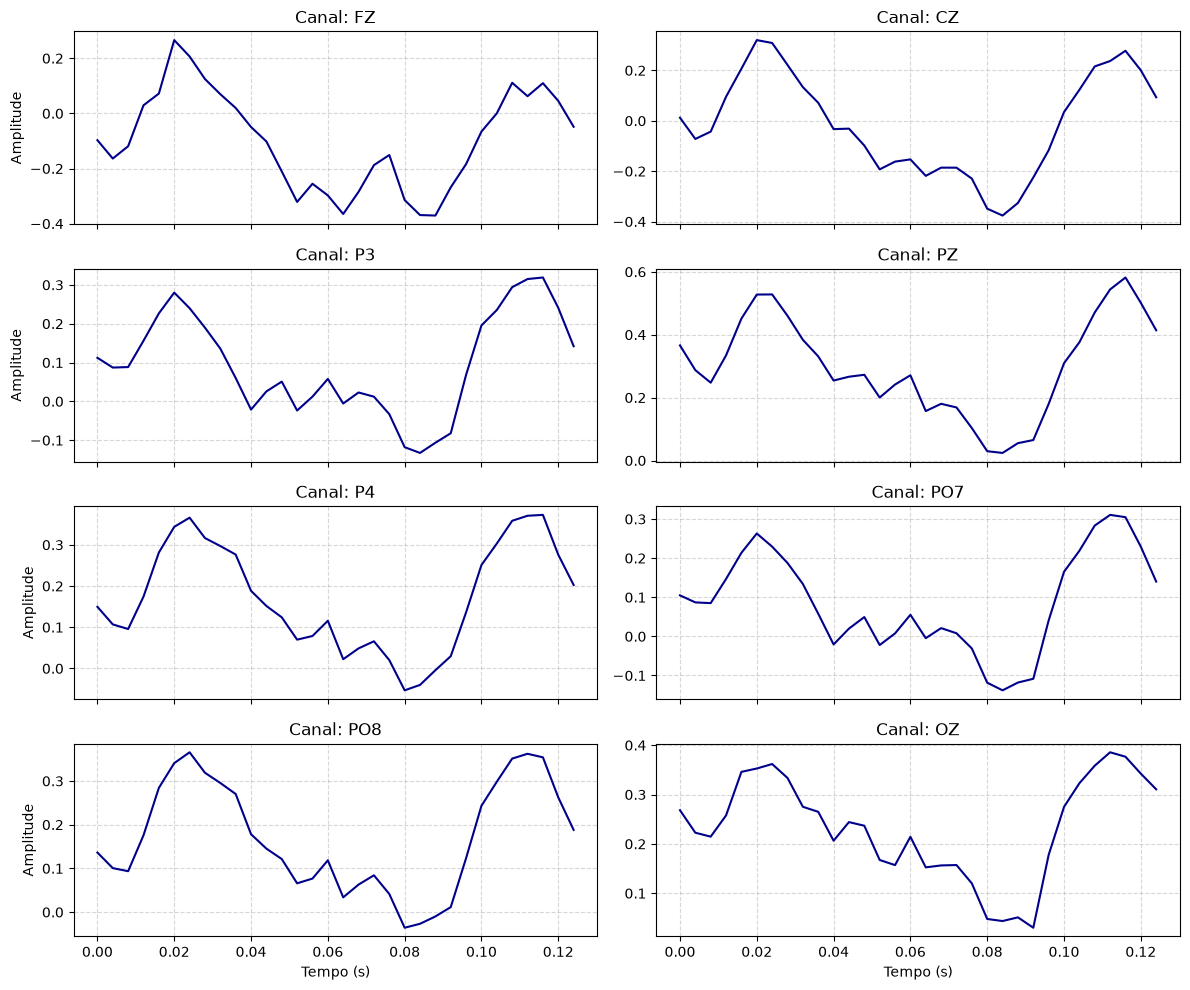

In [8]:
# plot filtrando pela média dos "misses"
plots_evoked(epochs["miss"].average())